# Step 3 — Line segmentation (row projection profile + gap tolerance)

`src/line_segmentation.py`: row profile p(y) = # ink pixels in row y; ink row if p(y) ≥ `INK_MIN` = 2. Two-state scan top → bottom (IDLE / IN-LINE): empty runs of ≤ G_max rows are bridged (fraction bar ↔ numerator / denominator), a longer run ends the line at its last ink row. Lines shorter than H_min are dropped. G_max = round(3w), H_min = round(3w), w = **stroke width from Step 1** (`params["stroke_w"]`, same value as `results["stroke_width"]` in the pipeline — not re-estimated). Lines are half-open `(start, end)`; crops are trimmed to their ink columns, box = (y0, y1, x0, x1) in page coordinates.
Input = Step-2 deskewed binary (Step 1 → Step 2 exactly as in `src/pipeline.py`). Spec: `Claude Chat Memory/Line_Segmentation.md`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import src.adaptive_thresholding as at
import src.skew_correction as sk
import src.line_segmentation as ls
print(f"INK_MIN={ls.INK_MIN}, GAP_K={ls.GAP_K}, MIN_H_K={ls.MIN_H_K}, R_MIN={sk.R_MIN}")

INK_MIN=2, GAP_K=3, MIN_H_K=3, R_MIN=2.8


In [2]:
photo_dir = ROOT / "data" / "raw" / "photos"
photos = [p for p in sorted(photo_dir.glob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]

pages = {}                                                   # name -> deskewed binary, w, theta
for i, p in enumerate(photos):
    binary, params = at.run_adaptive(p, return_params=True)  # Step 1 (block / C estimated)
    rot, info = sk.deskew(binary)                            # Step 2
    pages[f"photo {i + 1}"] = {"file": p.name, "binary": rot, "w": params["stroke_w"],
                               "theta": info["theta"], "fallback": info["fallback"]}
{k: (v["file"], f"w = {v['w']:g} px", f"θ = {v['theta']:.1f}°") for k, v in pages.items()}

{'photo 1': ('PHOTO-2026-11-20-23-54-12.jpg', 'w = 4 px', 'θ = -88.8°'),
 'photo 2': ('PHOTO-2026-11-21-01-41-35.jpg', 'w = 7 px', 'θ = 87.9°'),
 'photo 3': ('PHOTO-2026-11-21-22-38-16.jpg', 'w = 5 px', 'θ = 0.3°'),
 'photo 4': ('test.png', 'w = 6 px', 'θ = -29.8°')}

## 1. Per photo: line boxes | row profile p(y)
Left: deskewed binary (black ink on white), one rectangle per line (box from `crop_line`), labelled k. Right: p(y) sideways on the same rows, red dashed = `INK_MIN`, shaded = detected lines `[start, end)`.

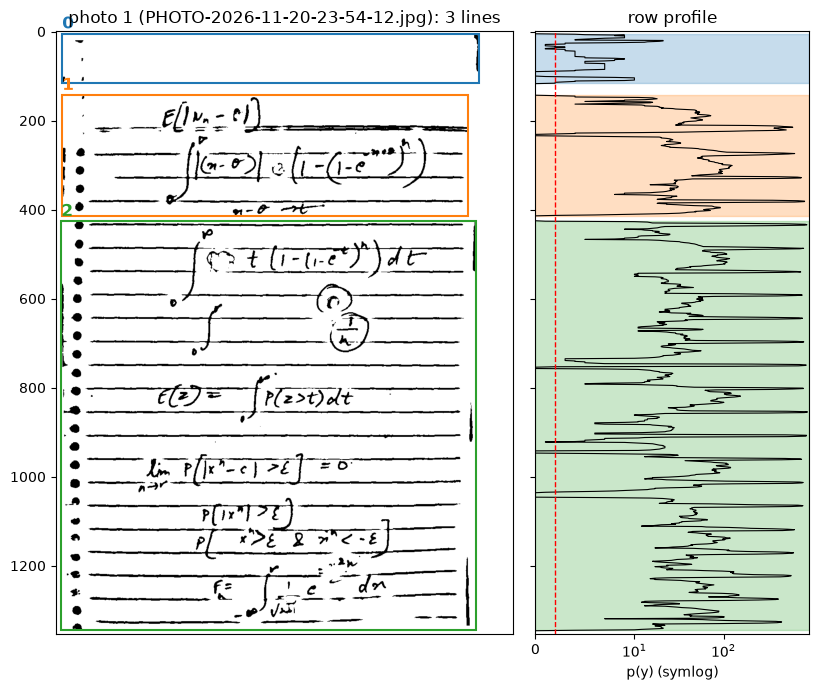

photo 1: w = 4 px, G_max = 12 px, H_min = 12 px, 3 lines: [(6, 117), (144, 414), (427, 1346)]


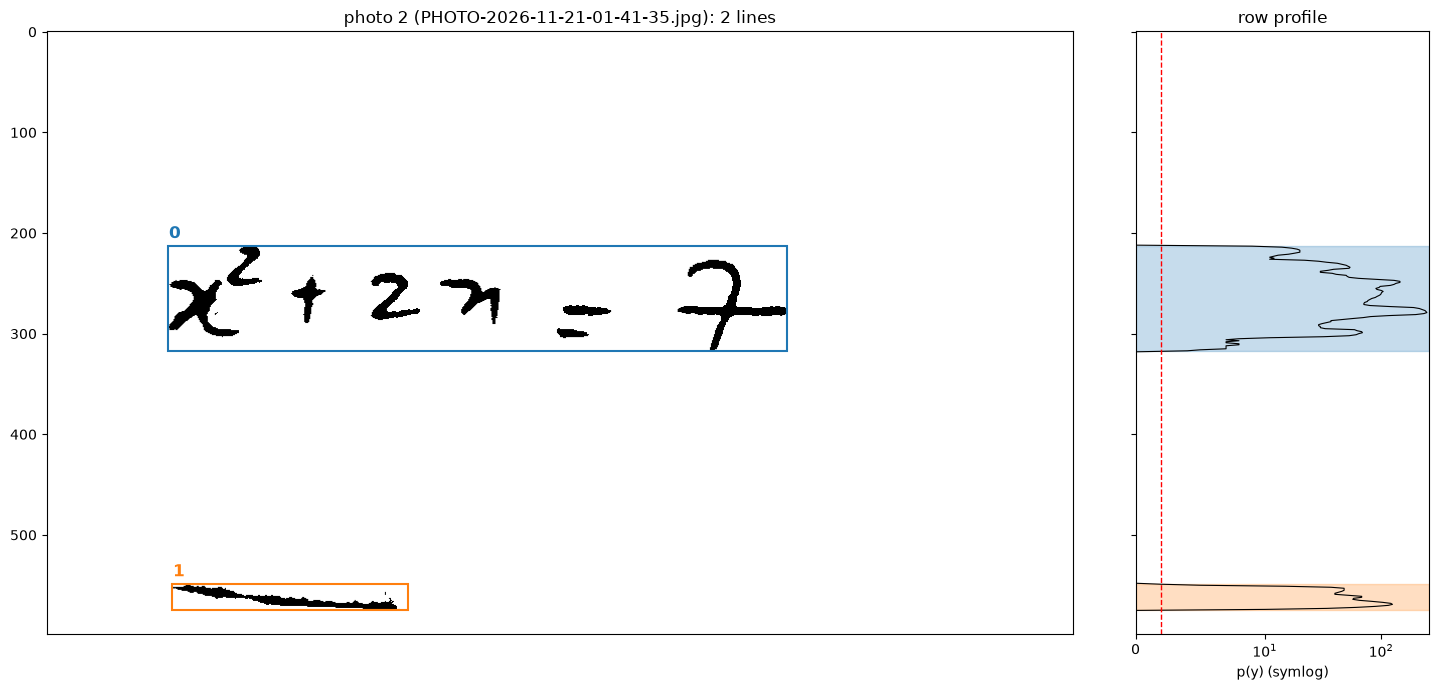

photo 2: w = 7 px, G_max = 21 px, H_min = 21 px, 2 lines: [(213, 318), (549, 575)]


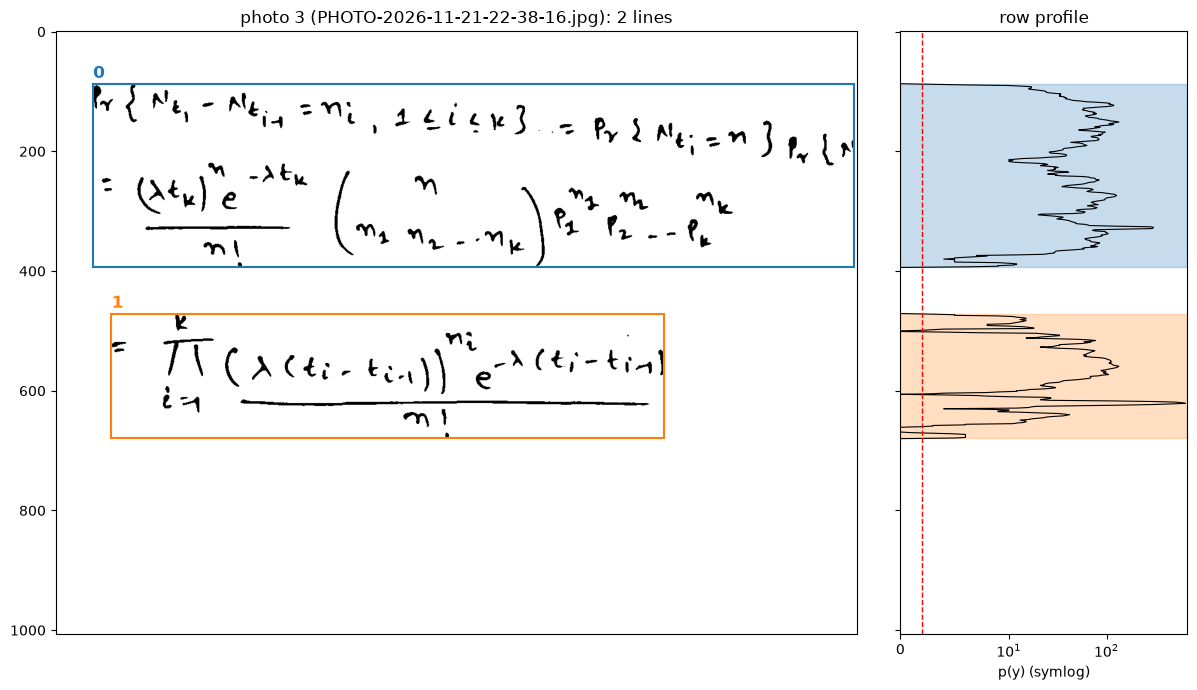

photo 3: w = 5 px, G_max = 15 px, H_min = 15 px, 2 lines: [(88, 394), (472, 680)]


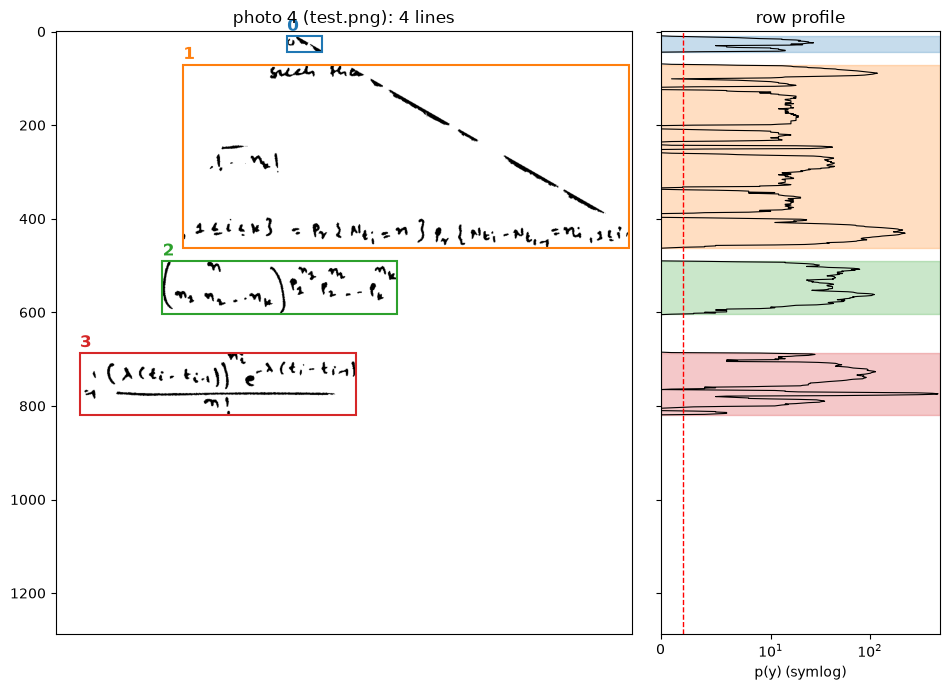

photo 4: w = 6 px, G_max = 18 px, H_min = 18 px, 4 lines: [(11, 44), (71, 462), (491, 604), (687, 819)]


In [3]:
results = {}
for name, pg in pages.items():
    b, w = pg["binary"], pg["w"]
    lines, info = ls.segment_lines(b, w)
    crops = [ls.crop_line(b, s, e) for s, e in lines]        # (crop, box)
    results[name] = {"lines": lines, "info": info, "crops": crops}

    H, W = b.shape
    fig, ax = plt.subplots(1, 2, figsize=(7 * W / H + 3, 7), sharey=True,
                           gridspec_kw={"width_ratios": [W / H, 0.45]})
    ax[0].imshow(255 - b, cmap="gray")
    for k, (_, (y0, y1, x0, x1)) in enumerate(crops):
        ax[0].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=f"C{k % 10}", lw=1.5))
        ax[0].text(x0, y0 - 4, str(k), color=f"C{k % 10}", fontsize=12, fontweight="bold", va="bottom")
    ax[0].set_title(f"{name} ({pg['file']}): {len(lines)} lines"); ax[0].set_xticks([])
    p = info["profile"]
    ax[1].plot(p, np.arange(H), lw=0.8, color="k")
    ax[1].axvline(info["ink_min"], color="r", ls="--", lw=1)
    for k, (s, e) in enumerate(lines):
        ax[1].axhspan(s - 0.5, e - 0.5, color=f"C{k % 10}", alpha=0.25)
    ax[1].set_xscale("symlog", linthresh=10); ax[1].set_xlim(left=0); ax[1].set_xlabel("p(y) (symlog)"); ax[1].set_title("row profile")
    plt.tight_layout(); plt.show()

    print(f"{name}: w = {w:g} px, G_max = {info['gap_max']} px, H_min = {info['min_h']} px, "
          f"{len(lines)} lines: {lines}")

## 2. Line-crop gallery
Each returned crop (trimmed to its ink columns); title = k and box (y0, y1, x0, x1).

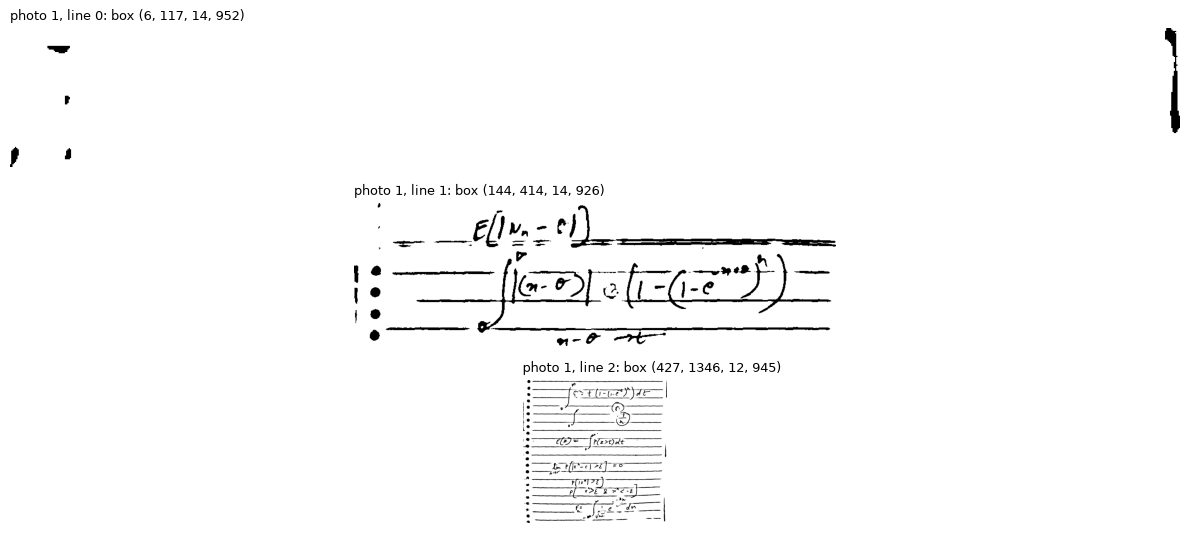

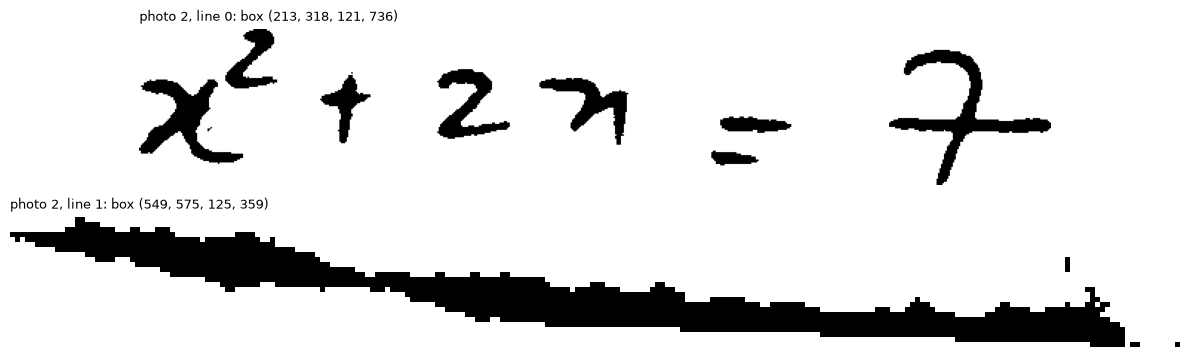

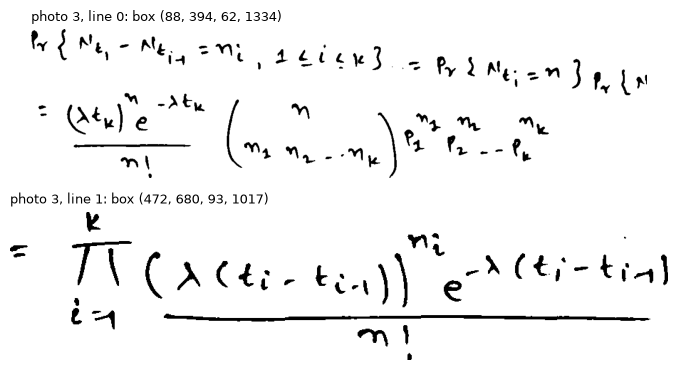

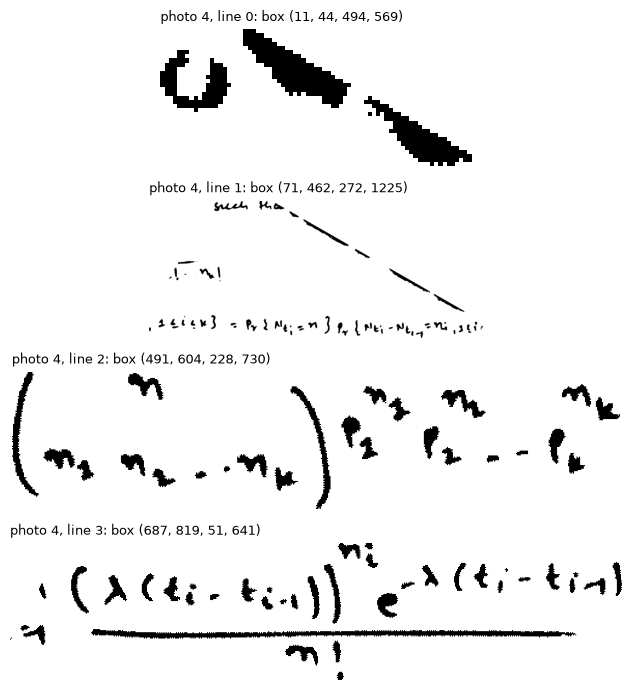

In [4]:
for name, res in results.items():
    n = len(res["crops"])
    if n == 0:
        print(f"{name}: no lines"); continue
    fig, ax = plt.subplots(n, 1, figsize=(12, 1.6 * n + 0.6), squeeze=False)
    for k, (crop, box) in enumerate(res["crops"]):
        ax[k, 0].imshow(255 - crop, cmap="gray", aspect="equal")
        ax[k, 0].set_title(f"{name}, line {k}: box {box}", fontsize=9, loc="left"); ax[k, 0].axis("off")
    plt.tight_layout(); plt.show()

## 3. Gap check
Runs of empty rows (p < `INK_MIN`) in px and in units of w, with position. Type: **border** (touches the top / bottom of the image), **inside** (bridged, inside a detected line), **between** (separates two detected lines), **dropped** (next to a band removed by H_min). Runs shorter than 0.5w are not listed (stroke gaps inside symbols).

== photo 1: w = 4 px, G_max = 12 px = 3.0w
   rows          len px   len/w   type
   [   0,    6)       6     1.5   border
   [  29,   33)       4     1.0   inside
   [  38,   40)       2     0.5   inside
   [  90,  102)      12     3.0   inside
   [ 117,  144)      27     6.8   between
   [ 231,  235)       4     1.0   inside
   [ 414,  427)      13     3.2   between
   [ 754,  758)       4     1.0   inside
   [ 942,  948)       6     1.5   inside
   [1035, 1047)      12     3.0   inside
   [1346, 1354)       8     2.0   border
== photo 2: w = 7 px, G_max = 21 px = 3.0w
   rows          len px   len/w   type
   [   0,  213)     213    30.4   border
   [ 318,  549)     231    33.0   between
   [ 575,  599)      24     3.4   border
== photo 3: w = 5 px, G_max = 15 px = 3.0w
   rows          len px   len/w   type
   [   0,   88)      88    17.6   border
   [ 394,  472)      78    15.6   between
   [ 661,  671)      10     2.0   inside
   [ 680, 1007)     327    65.4   border
== photo 4: 

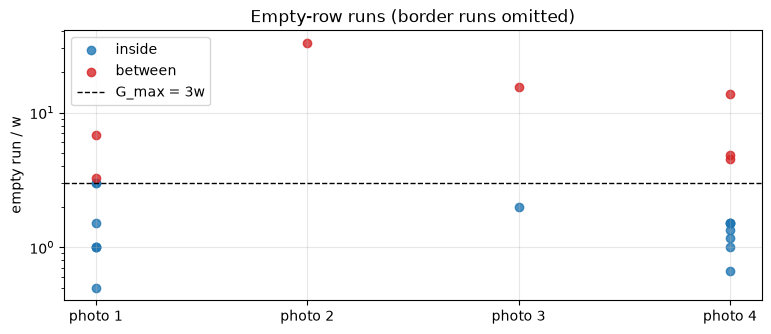

In [5]:
def empty_runs(profile, ink_min):
    # half-open runs [a, b) of rows with p < ink_min
    empty = np.r_[False, profile < ink_min, False].astype(np.int8)
    d = np.diff(empty)
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))

gap_rows = []
for name, res in results.items():
    info, lines, w = res["info"], res["lines"], pages[name]["w"]
    H = len(info["profile"])
    print(f"== {name}: w = {w:g} px, G_max = {info['gap_max']} px = {info['gap_max'] / w:.1f}w")
    print("   rows          len px   len/w   type")
    for a, b_ in empty_runs(info["profile"], info["ink_min"]):
        if b_ - a < 0.5 * w:
            continue
        if a == 0 or b_ == H:
            kind = "border"
        elif any(s <= a and b_ <= e for s, e in lines):
            kind = "inside"
        elif any(e == a for s, e in lines) and any(s == b_ for s, e in lines):
            kind = "between"
        else:
            kind = "dropped"
        gap_rows.append((name, a, b_, (b_ - a) / w, kind))
        print(f"   [{a:4d}, {b_:4d})  {b_ - a:6d}  {(b_ - a) / w:6.1f}   {kind}")

plt.figure(figsize=(9, 3.5))
names = list(results)
for kind, c in [("inside", "C0"), ("between", "C3"), ("dropped", "C7")]:
    pts = [(names.index(n), g) for n, _, _, g, t in gap_rows if t == kind]
    if pts:
        plt.scatter(*zip(*pts), color=c, label=kind, alpha=0.8)
plt.axhline(ls.GAP_K, color="k", ls="--", lw=1, label=f"G_max = {ls.GAP_K}w")
plt.yscale("log"); plt.xticks(range(len(names)), names); plt.ylabel("empty run / w")
plt.legend(); plt.grid(alpha=0.3); plt.title("Empty-row runs (border runs omitted)"); plt.show()

## 4. Photo 3: why are lines 1 and 2 merged?
Two candidate causes: the vertical timestamp in the left margin (spans the rows of both lines) or strokes of line 1 and line 2 touching vertically (sub/superscripts). Blank the left margin and segment again; zoom on the rows around the profile minimum between the two lines.

original:       [(88, 394), (472, 680)]
margin blanked: [(88, 394), (472, 680)]
profile minimum between the two lines: row 214, p = 10 (INK_MIN = 2)


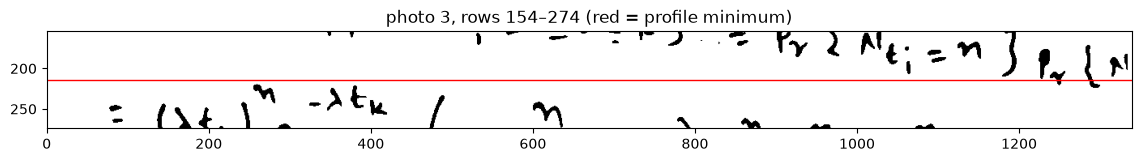

In [6]:
b3, w3 = pages["photo 3"]["binary"], pages["photo 3"]["w"]
masked = b3.copy(); masked[:, :60] = 0                       # blank the margin timestamp
print("original:      ", results["photo 3"]["lines"])
print("margin blanked:", ls.segment_lines(masked, w3)[0])

p3 = ls.row_profile(masked)
y_min = 150 + int(np.argmin(p3[150:300]))                  # rows between line-1 and line-2 cores (by eye)
print(f"profile minimum between the two lines: row {y_min}, p = {p3[y_min]} (INK_MIN = {ls.INK_MIN})")
fig, ax = plt.subplots(figsize=(14, 4))
ax.imshow(255 - masked[y_min - 60:y_min + 60], cmap="gray", extent=(0, b3.shape[1], y_min + 60, y_min - 60))
ax.axhline(y_min, color="r", lw=1); ax.set_title(f"photo 3, rows {y_min - 60}–{y_min + 60} (red = profile minimum)")
plt.show()

## 5. Observations

Table measured with the **adaptive-mean** Step 1 (previous version; see the note below for adaptive Otsu):

| Photo | Expected lines | Detected | Correct? | Failure reason |
|---|---|---|---|---|
| 1 (lined page, θ = −88.8°) | 9 expressions | 1 (whole page) | no | **ruled lines** (+ spiral holes, margin line) put ink in every row; the only empty run is 4 rows at the bottom. Expected, out of scope. |
| 2 (`x²+2x=7`, upside-down) | 1 | 2 | expression ✓ (line 1) | line 0 = **page edge** at the top (false line). Speck pair at row ~560 dropped by H_min ✓. |
| 3 (upright derivation) | 3 | 3 | 1 of 3 (line 1, fraction bridged) | line 0 = lines 1 + 2 **merged**: line 1 slopes down ~4° to the right (see notebook 03), its right end (`Pr{N_ti = n} Pr{N`) dips into the top rows of line 2. Minimum of p between them is 15 (row 214), not < 2. Not caused by the margin timestamp (blanking it moves only the start 35 → 83). Line 2 = **table / page edge** at the bottom (false line). |
| 4 (`test.png`, tilted derivation, θ = −29.8°) | 6 (4 partial at the top) | 3 | 2 of 3 (binomial line, fraction line) | line 0 merges the 4 partial lines (`o…`, `such tha`, `!…n_k!`, `1≤i≤k}…`): the **diagonal page-shadow edge** crosses all their gaps. Two specks at rows ~1000–1046 dropped by H_min ✓. |

- **Gaps (section 3):** inside math lines ≤ 1.2w (fraction bar ↔ numerator / denominator, scripts); between real lines 5.2w – 33.7w. G_max = 3w separates them, consistent with the spec's first test (≤ 2w / ≥ 4.4w). The two bridged runs closest to G_max (2.5w photo 3, 2.8w photo 4) are both around non-math ink (margin timestamp specks, page edge).
- **No fraction was split**; no speck "line" survived H_min.
- Every failure comes from **non-text ink** (page edges, shadow edge, ruled lines) or **per-line tilt**, not from the thresholds: the border / large-blob filter pending from Step 2 should likely remove the false lines of photos 2, 3 and the merge in photo 4 (to check once the filter exists); photo 3's merge needs a cut at the profile minimum or CC-to-line assignment in Step 4; photo 1 needs ruled-line removal.
- Crop of photo 4 line 1 starts at x = 175 because of a speck left of the bracket → box wider than the text; Step 4 drops tiny blobs.

**With adaptive Otsu (current Step 1, outputs above):**
- Photo 1 (θ = −88.8°): 3 lines [(6, 117), (144, 414), (427, 1346)] — cut only where ruled lines leave gaps; still wrong (ruled lines), as before.
- Photo 2 (θ = 87.9°, now upright): [(213, 318), (549, 575)] = expression ✓ + **page edge** below it (false line, now at the bottom).
- Photo 3: 2 lines [(88, 394), (472, 680)] — lines 1 + 2 still merged (same cause), line 3 ✓; the **false table-edge line is gone** (shadow tiles are now all paper) and the margin timestamp no longer forms a line.
- Photo 4: 4 lines [(11, 44), (71, 462), (491, 604), (687, 819)] — same as with adaptive mean (partial top line, merged partial lines, binomial line ✓, fraction line ✓).